# Analyses métier : performance des façonniers

**Question posée :** qu'est-ce qui dégrade la performance de la sous-traitance de DermaLab (délais, quantités, qualité) ?

**Démarche :** on part uniquement des données nettoyées par le pipeline Alteryx (`data/processed/`) et du référentiel produits de l'ERP. On pose des questions métier et on laisse les chiffres répondre, sans hypothèse préalable. Les tables de vérité (`data/reference/verite/`) ne sont ouvertes qu'à la toute fin, pour valider les constats.

**Indicateurs** (règles du `config.yaml`) :
| Indicateur | Définition |
|---|---|
| À l'heure (*On Time*) | livrée au plus tard 2 jours après la date promise |
| Complète (*In Full*) | quantité conforme ≥ 98 % de la quantité commandée |
| **OTIF** | à l'heure **et** complète |
| Taux de rejet | part des lots au statut « rejeté » |

**Plan :** 1. Table d'analyse · 2. Vue d'ensemble · 3. Quel façonnier se dégrade ? · 4. Y a-t-il une saisonnalité ? · 5. Qu'est-ce qui explique les rejets ? · 6. Déviations qualité · 7. Synthèse · 8. Validation · 9. Export

In [1]:
import math
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Racine du projet (fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine)
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Règles métier (config.yaml)
TOLERANCE_RETARD_J = 2
SEUIL_IN_FULL = 0.98
FIN_PERIODE = pd.Timestamp("2025-12-31")   # fin de la période étudiée

# Style des graphiques : une couleur d'accent pour la série étudiée, du gris pour le contexte
ACCENT, CONTEXTE, ENCRE, GRILLE = "#2a78d6", "#a3a29d", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE, "xtick.color": ENCRE, "ytick.color": ENCRE,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.precision", 3)


def test_deux_proportions(succes_a, n_a, succes_b, n_b):
    # Test z de comparaison de deux proportions (bilatéral) : renvoie (z, p-value)
    p_a, p_b = succes_a / n_a, succes_b / n_b
    p = (succes_a + succes_b) / (n_a + n_b)
    se = math.sqrt(p * (1 - p) * (1 / n_a + 1 / n_b))
    z = (p_a - p_b) / se if se > 0 else 0.0
    p_value = math.erfc(abs(z) / math.sqrt(2))
    return z, p_value


def formater_p(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


def enregistrer(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", bbox_inches="tight", dpi=150)

## 1. Table d'analyse

On charge les sorties Alteryx, puis on construit une table d'analyse des commandes enrichie de la gamme et de la complexité du produit.

**Périmètre :** l'OTIF ne se calcule que sur les commandes **livrées** dont la date de livraison et la quantité conforme sont connues. Les commandes en cours et celles dont une valeur a été invalidée par le pipeline (traçées dans `dq_anomalies`) sont écartées du calcul, et on le documente.

In [2]:
commandes = pd.read_csv(PROCESSED / "fact_commande.csv",
                        parse_dates=["date_commande", "date_promise", "date_livraison"])
lots = pd.read_csv(PROCESSED / "fact_lot.csv", parse_dates=["date_fabrication"])
deviations = pd.read_csv(PROCESSED / "fact_deviation.csv", parse_dates=["date_ouverture", "date_cloture"])
produits = pd.read_csv(RACINE / "data" / "raw" / "erp" / "erp_produits.csv", sep=";", decimal=",")

inventaire = pd.DataFrame({
    nom: {"lignes": len(df), "colonnes": df.shape[1], "cellules vides": int(df.isna().sum().sum())}
    for nom, df in {"commandes": commandes, "lots": lots, "deviations": deviations, "produits": produits}.items()
}).T
inventaire

,lignes,colonnes,cellules vides
commandes,6000,16,6380
lots,11735,8,0
deviations,1223,13,1267
produits,60,7,0


In [3]:
cmd = commandes.merge(produits[["sku", "gamme", "complexite"]], on="sku", how="left")
cmd["gamme"] = cmd["gamme"].fillna("SKU inconnu")
cmd["complexite"] = cmd["complexite"].astype("Int64")

cmd["retard_jours"] = (cmd["date_livraison"] - cmd["date_promise"]).dt.days
cmd["a_l_heure"] = cmd["retard_jours"] <= TOLERANCE_RETARD_J
cmd["complete"] = cmd["qte_conforme"] >= SEUIL_IN_FULL * cmd["qte_commandee"]
cmd["otif"] = cmd["a_l_heure"] & cmd["complete"]
cmd["mois"] = cmd["date_promise"].dt.to_period("M").dt.to_timestamp()
cmd["trimestre"] = cmd["date_promise"].dt.to_period("Q").astype(str)
cmd["mois_num"] = cmd["date_promise"].dt.month
cmd["annee"] = cmd["date_promise"].dt.year

livree = cmd["statut_commande"].eq("livrée")
dans_periode = cmd["date_promise"] <= FIN_PERIODE
mesurable = livree & cmd["date_livraison"].notna() & cmd["qte_conforme"].notna() & dans_periode
cmd["dans_perimetre_otif"] = mesurable
otif = cmd[mesurable].copy()

perimetre = pd.Series({
    "Commandes (après dédoublonnage)": len(cmd),
    "  dont en cours (non livrées)": int((~livree).sum()),
    "  dont livrées sans date de livraison": int((livree & cmd["date_livraison"].isna()).sum()),
    "  dont livrées sans quantité conforme valide": int((livree & cmd["date_livraison"].notna() & cmd["qte_conforme"].isna()).sum()),
    "  dont date promise après fin 2025 (mois incomplet)": int((livree & cmd["date_livraison"].notna() & cmd["qte_conforme"].notna() & ~dans_periode).sum()),
    "Commandes retenues pour l'OTIF": len(otif),
}, name="nombre")
perimetre.to_frame()

,nombre
Commandes (après dédoublonnage),6000
dont en cours (non livrées),179
dont livrées sans date de livraison,150
dont livrées sans quantité conforme valide,0
dont date promise après fin 2025 (mois incomplet),14
Commandes retenues pour l'OTIF,5657


## 2. Vue d'ensemble

La photo qu'un responsable de la sous-traitance regarderait en premier : performance de livraison et qualité, par façonnier.

In [4]:
lots_p = lots.merge(produits[["sku", "gamme", "complexite"]], on="sku", how="left")
lots_p["complexite"] = lots_p["complexite"].astype("Int64")
lots_p["rejete"] = lots_p["statut_lot"].eq("rejeté")
lots_p["retraite"] = lots_p["statut_lot"].eq("retraité")
lots_p["avec_deviation"] = lots_p["id_lot"].isin(deviations["id_lot"])
lots_p["gros_lot"] = lots_p["taille_lot"] > 50_000

noms = cmd.drop_duplicates("id_facconnier").set_index("id_facconnier")["nom_facconnier"]

kpi_livraison = otif.groupby("id_facconnier").agg(
    commandes=("id_commande", "size"),
    a_l_heure=("a_l_heure", "mean"),
    complete=("complete", "mean"),
    otif=("otif", "mean"),
)
kpi_qualite = lots_p.groupby("id_facconnier").agg(
    lots=("id_lot", "size"),
    taux_rejet=("rejete", "mean"),
    taux_retraitement=("retraite", "mean"),
    taux_deviation=("avec_deviation", "mean"),
)
vue = kpi_livraison.join(kpi_qualite)
vue.insert(0, "nom", noms)

total = pd.DataFrame({
    "nom": ["TOUS"], "commandes": [len(otif)], "a_l_heure": [otif["a_l_heure"].mean()],
    "complete": [otif["complete"].mean()], "otif": [otif["otif"].mean()], "lots": [len(lots_p)],
    "taux_rejet": [lots_p["rejete"].mean()], "taux_retraitement": [lots_p["retraite"].mean()],
    "taux_deviation": [lots_p["avec_deviation"].mean()],
}, index=["Total"])
vue = pd.concat([vue, total])

pct = ["a_l_heure", "complete", "otif", "taux_rejet", "taux_retraitement", "taux_deviation"]
print(f"Note : {int(lots_p['complexite'].isna().sum())} lots portent un SKU inconnu de l'ERP (anomalie tracée) : ils n'ont ni gamme ni complexité.")
vue.style.format({c: "{:.1%}" for c in pct}).background_gradient(subset=["otif"], cmap="Blues")

Note : 120 lots portent un SKU inconnu de l'ERP (anomalie tracée) : ils n'ont ni gamme ni complexité.


,nom,commandes,a_l_heure,complete,otif,lots,taux_rejet,taux_retraitement,taux_deviation
F01,Cosmétiques du Midi,363,96.4%,93.1%,89.8%,754,1.9%,2.4%,8.9%
F02,Laboratoires Garonne Façonnage,680,93.4%,92.6%,86.5%,1400,2.4%,3.2%,9.9%
F03,Fabrication Pyrénées,1724,95.1%,90.4%,86.1%,3640,3.3%,4.5%,11.9%
F04,Atlantique Formulation,1014,92.2%,92.6%,85.3%,2111,2.4%,2.8%,9.8%
F05,Valencia Cosmetic Partners,526,87.8%,91.4%,79.7%,1091,2.8%,2.9%,8.9%
F06,Wisla Contract Manufacturing,367,88.6%,94.3%,83.1%,765,2.1%,2.6%,8.6%
F07,Andalucía Dermo Industrial,493,87.0%,90.1%,78.3%,1011,3.1%,3.3%,10.7%
F08,Toscana Beauty Lab,490,92.4%,90.6%,83.7%,963,3.2%,2.3%,11.1%
Total,TOUS,5657,92.4%,91.6%,84.6%,11735,2.8%,3.3%,10.4%


**Lecture :** un OTIF global qui paraît correct peut masquer des écarts importants entre façonniers et dans le temps. Une moyenne sur 3 ans ne dit pas si la situation **se dégrade** : c'est l'objet de la question suivante.

## 3. Quel façonnier se dégrade, et depuis quand ?

On regarde d'abord l'OTIF par façonnier et par trimestre, pour repérer une évolution sans a priori.

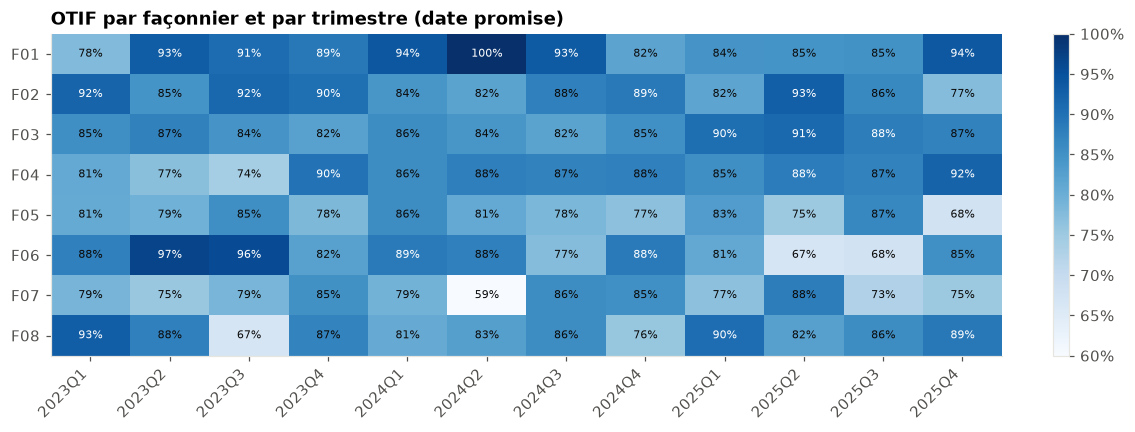

In [5]:
heat = otif.pivot_table(index="id_facconnier", columns="trimestre", values="otif", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(heat.values, cmap="Blues", vmin=0.6, vmax=1.0, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=45, ha="right")
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.88 else "#0b0b0b")
ax.set_title("OTIF par façonnier et par trimestre (date promise)")
fig.colorbar(im, ax=ax, fraction=0.02, format=lambda x, _: f"{x:.0%}")
enregistrer(fig, "01_otif_facconnier_trimestre")
plt.show()

Pour objectiver ce qu'on voit, on compare pour chaque façonnier l'OTIF de la dernière année (2025) à celui des deux années précédentes, avec un test de comparaison de proportions.

In [6]:
lignes = []
for f, g in otif.groupby("id_facconnier"):
    avant, apres = g[g["annee"] < 2025], g[g["annee"] == 2025]
    z, p = test_deux_proportions(apres["otif"].sum(), len(apres), avant["otif"].sum(), len(avant))
    lignes.append({"façonnier": f, "OTIF 2023-2024": avant["otif"].mean(), "OTIF 2025": apres["otif"].mean(),
                   "écart (pts)": 100 * (apres["otif"].mean() - avant["otif"].mean()), "p-value": p})
evolution = pd.DataFrame(lignes).set_index("façonnier").sort_values("écart (pts)")
evolution.style.format({"OTIF 2023-2024": "{:.1%}", "OTIF 2025": "{:.1%}",
                        "écart (pts)": "{:+.1f}", "p-value": formater_p})

,OTIF 2023-2024,OTIF 2025,écart (pts),p-value
façonnier,,,,
F06,87.4%,75.0%,-12.4,"0,002"
F01,91.2%,87.0%,-4.3,"0,204"
F05,80.7%,77.5%,-3.3,"0,380"
F02,87.4%,84.6%,-2.8,"0,306"
F07,78.1%,78.7%,+0.7,"0,861"
F04,83.7%,88.3%,+4.6,"0,049"
F03,84.5%,89.3%,+4.8,"0,007"
F08,81.9%,87.0%,+5.1,"0,150"


In [7]:
# Le façonnier qui se dégrade le plus est identifié par les données, pas choisi à la main
cible = evolution.index[0]

# Recherche du mois de rupture : on teste chaque mois candidat comme « début de la dégradation »
# et on retient celui qui sépare le mieux l'avant et l'après (z le plus élevé)
g = otif[otif["id_facconnier"] == cible]
candidats = pd.date_range("2023-07-01", "2025-09-01", freq="MS")
scores = []
for m in candidats:
    avant, apres = g[g["mois"] < m], g[g["mois"] >= m]
    z, p = test_deux_proportions(avant["otif"].sum(), len(avant), apres["otif"].sum(), len(apres))
    scores.append((m, z))
rupture = max(scores, key=lambda t: t[1])[0]

avant, apres = g[g["mois"] < rupture], g[g["mois"] >= rupture]
z, p = test_deux_proportions(avant["otif"].sum(), len(avant), apres["otif"].sum(), len(apres))
autres = otif[(otif["id_facconnier"] != cible) & (otif["mois"] >= rupture)]

print(f"Façonnier le plus dégradé : {cible} ({noms[cible]})")
print(f"Rupture détectée : {rupture:%m/%Y}")
print(f"OTIF avant : {avant['otif'].mean():.1%} ({len(avant)} commandes)")
print(f"OTIF après : {apres['otif'].mean():.1%} ({len(apres)} commandes), p-value {formater_p(p)}")
print(f"  dont à l'heure : {avant['a_l_heure'].mean():.1%} -> {apres['a_l_heure'].mean():.1%}")
print(f"  dont complète  : {avant['complete'].mean():.1%} -> {apres['complete'].mean():.1%}")
print(f"OTIF des autres façonniers sur la même période : {autres['otif'].mean():.1%}")

Façonnier le plus dégradé : F06 (Wisla Contract Manufacturing)
Rupture détectée : 02/2025
OTIF avant : 87.7% (253 commandes)
OTIF après : 72.8% (114 commandes), p-value < 0,001
  dont à l'heure : 92.9% -> 78.9%
  dont complète  : 94.9% -> 93.0%
OTIF des autres façonniers sur la même période : 85.5%


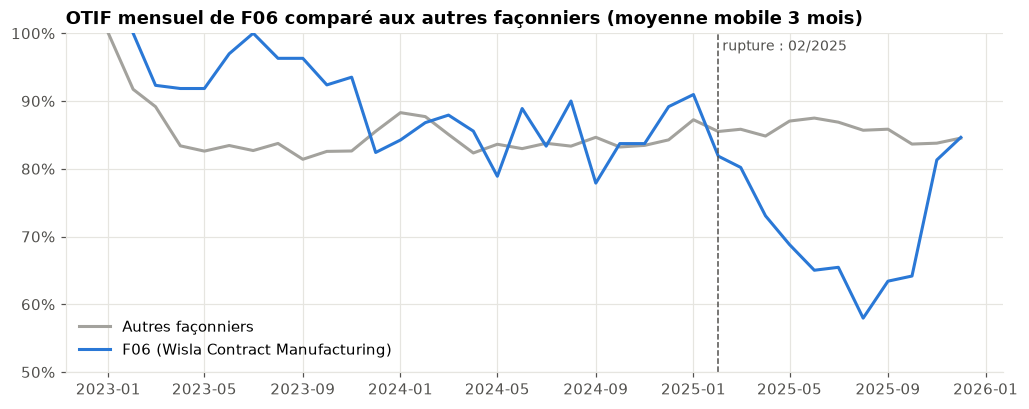

In [8]:
mensuel = otif.assign(groupe=np.where(otif["id_facconnier"] == cible, cible, "Autres façonniers")) \
              .groupby(["mois", "groupe"])["otif"].mean().unstack()
lisse = mensuel.rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(lisse.index, lisse["Autres façonniers"], color=CONTEXTE, linewidth=2, label="Autres façonniers")
ax.plot(lisse.index, lisse[cible], color=ACCENT, linewidth=2, label=f"{cible} ({noms[cible]})")
ax.legend(frameon=False, loc="lower left")
ax.axvline(rupture, color=ENCRE, linestyle="--", linewidth=1)
ax.text(rupture, 0.99, f" rupture : {rupture:%m/%Y}", color=ENCRE, va="top", fontsize=9)
ax.set_ylim(0.5, 1.0)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title(f"OTIF mensuel de {cible} comparé aux autres façonniers (moyenne mobile 3 mois)")
enregistrer(fig, "02_rupture_otif")
plt.show()

**Lecture :** la dégradation commence début 2025. Le mois exact de rupture est estimé à un mois près, car le façonnier ne reçoit qu'une douzaine de commandes par mois : un mois isolé peut être bas par hasard. Ce qui compte pour le métier, c'est que la baisse est **nette, durable sur plusieurs trimestres et propre à ce façonnier**. La remontée visible fin 2025 est à surveiller avant de conclure à un retour à la normale.

## 4. Y a-t-il une saisonnalité ?

On croise la gamme de produits et le mois de la date promise, sur le taux de livraison à l'heure.

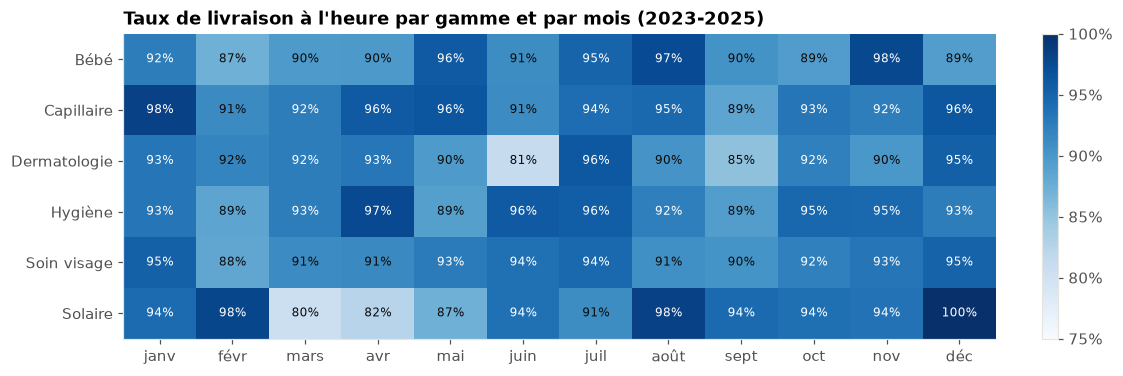

In [9]:
saison = otif[otif["gamme"] != "SKU inconnu"].pivot_table(
    index="gamme", columns="mois_num", values="a_l_heure", aggfunc="mean")
mois_lib = ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"]

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(saison.values, cmap="Blues", vmin=0.75, vmax=1.0, aspect="auto")
ax.set_xticks(range(12), mois_lib)
ax.set_yticks(range(saison.shape[0]), saison.index)
ax.grid(False)
for i in range(saison.shape[0]):
    for j in range(saison.shape[1]):
        v = saison.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.92 else "#0b0b0b")
ax.set_title("Taux de livraison à l'heure par gamme et par mois (2023-2025)")
fig.colorbar(im, ax=ax, fraction=0.02, format=lambda x, _: f"{x:.0%}")
enregistrer(fig, "03_saisonnalite_gamme_mois")
plt.show()

Une saisonnalité doit **revenir chaque année**. On vérifie donc gamme par gamme et année par année l'écart entre mars-mai et le reste de l'année. Pour ne pas mélanger deux effets, on exclut ici les commandes du façonnier dégradé après sa rupture.

In [10]:
base = otif[(otif["gamme"] != "SKU inconnu") & ~((otif["id_facconnier"] == cible) & (otif["mois"] >= rupture))]
base = base.assign(printemps=base["mois_num"].isin([3, 4, 5]))

lignes = []
for gamme, g in base.groupby("gamme"):
    pr, reste = g[g["printemps"]], g[~g["printemps"]]
    z, p = test_deux_proportions(pr["a_l_heure"].sum(), len(pr), reste["a_l_heure"].sum(), len(reste))
    ligne = {"gamme": gamme, "à l'heure mars-mai": pr["a_l_heure"].mean(),
             "à l'heure reste de l'année": reste["a_l_heure"].mean(),
             "écart (pts)": 100 * (pr["a_l_heure"].mean() - reste["a_l_heure"].mean()), "p-value": p}
    for an in (2023, 2024, 2025):
        ga = g[g["annee"] == an]
        ligne[f"écart {an}"] = 100 * (ga[ga["printemps"]]["a_l_heure"].mean() - ga[~ga["printemps"]]["a_l_heure"].mean())
    lignes.append(ligne)
saisonnalite = pd.DataFrame(lignes).set_index("gamme").sort_values("écart (pts)")
saisonnalite.style.format({"à l'heure mars-mai": "{:.1%}", "à l'heure reste de l'année": "{:.1%}",
                           "écart (pts)": "{:+.1f}", "écart 2023": "{:+.1f}", "écart 2024": "{:+.1f}",
                           "écart 2025": "{:+.1f}", "p-value": formater_p})

,à l'heure mars-mai,à l'heure reste de l'année,écart (pts),p-value,écart 2023,écart 2024,écart 2025
gamme,,,,,,,
Solaire,84.8%,95.7%,-10.9,"< 0,001",-7.0,-18.0,-8.0
Bébé,91.6%,92.0%,-0.5,"0,850",-5.8,-1.3,+5.1
Soin visage,92.6%,92.7%,-0.1,"0,950",+0.4,+0.2,-0.8
Hygiène,93.5%,93.3%,+0.2,"0,920",+2.5,-1.8,+0.1
Dermatologie,91.7%,90.8%,+0.9,"0,686",-1.0,+1.3,+2.6
Capillaire,95.0%,93.2%,+1.7,"0,329",-1.7,+2.6,+4.1


## 5. Qu'est-ce qui explique les rejets de lots ?

On compare le taux de rejet selon la complexité du produit (1 = simple, 3 = complexe).

Complexité 3 : 4.59% de rejets, contre 2.37% pour 1-2 (x1.9, p-value < 0,001)


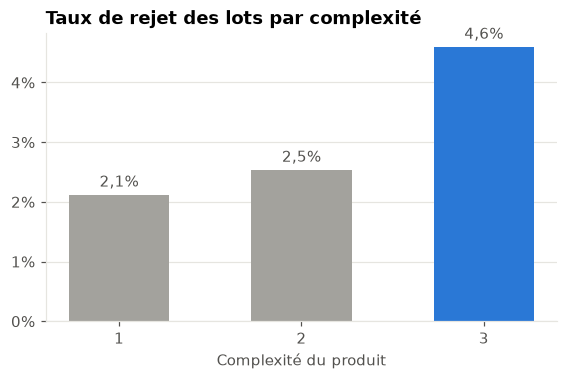

,lots,rejetes,taux_rejet
complexite,,,
1,3682,78,2.12%
2,5800,147,2.53%
3,2133,98,4.59%


In [11]:
par_complexite = lots_p.groupby("complexite").agg(lots=("id_lot", "size"), rejetes=("rejete", "sum"),
                                                   taux_rejet=("rejete", "mean"))
c3 = lots_p[lots_p["complexite"] == 3]
c12 = lots_p[lots_p["complexite"] < 3]
z, p_rejet = test_deux_proportions(c3["rejete"].sum(), len(c3), c12["rejete"].sum(), len(c12))
ratio_rejet = c3["rejete"].mean() / c12["rejete"].mean()
print(f"Complexité 3 : {c3['rejete'].mean():.2%} de rejets, contre {c12['rejete'].mean():.2%} pour 1-2 "
      f"(x{ratio_rejet:.1f}, p-value {formater_p(p_rejet)})")

fig, ax = plt.subplots(figsize=(6, 3.4))
couleurs = [CONTEXTE, CONTEXTE, ACCENT]
barres = ax.bar(par_complexite.index.astype(str), par_complexite["taux_rejet"], color=couleurs, width=0.55)
ax.bar_label(barres, labels=[f"{v:.1%}".replace(".", ",") for v in par_complexite["taux_rejet"]], padding=3, color=ENCRE)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Complexité du produit")
ax.grid(axis="x", visible=False)
ax.set_title("Taux de rejet des lots par complexité")
enregistrer(fig, "04_rejet_complexite")
plt.show()
par_complexite.style.format({"taux_rejet": "{:.2%}"})

**Piège classique :** si les produits complexes sont surtout fabriqués par les façonniers les moins bons, l'effet « complexité » pourrait en réalité être un effet « façonnier ». On contrôle en regardant le taux de rejet par complexité **à l'intérieur de chaque façonnier**.

In [12]:
controle = lots_p.pivot_table(index="id_facconnier", columns="complexite", values="rejete", aggfunc="mean")
controle.columns = [f"complexité {c}" for c in controle.columns]
controle["ratio 3 / (1-2)"] = controle["complexité 3"] / lots_p[lots_p["complexite"] < 3] \
    .groupby("id_facconnier")["rejete"].mean()
controle["part de lots complexité 3"] = lots_p.groupby("id_facconnier")["complexite"].apply(lambda s: (s == 3).mean())
print(f"Le taux de rejet est plus élevé en complexité 3 chez {int((controle['ratio 3 / (1-2)'] > 1).sum())} façonniers sur {len(controle)}.")
controle.style.format({c: "{:.1%}" for c in controle.columns if c != "ratio 3 / (1-2)"} | {"ratio 3 / (1-2)": "x{:.1f}"})

Le taux de rejet est plus élevé en complexité 3 chez 7 façonniers sur 8.


,complexité 1,complexité 2,complexité 3,ratio 3 / (1-2),part de lots complexité 3
id_facconnier,,,,,
F01,1.8%,1.9%,2.2%,x1.2,6.0%
F02,1.8%,1.8%,3.5%,x2.0,34.9%
F03,1.6%,2.6%,6.5%,x2.7,20.4%
F04,2.6%,1.8%,3.3%,x1.5,18.7%
F05,1.5%,3.0%,nan%,xnan,0.0%
F06,1.1%,2.4%,3.0%,x1.6,27.0%
F07,2.4%,3.3%,4.4%,x1.5,11.4%
F08,2.8%,3.1%,4.9%,x1.7,17.1%


## 6. Déviations qualité

Les déviations n'ont pas de catégorie de cause dans les données sources : seule une **description en texte libre** est disponible. On analyse ici ce qui est mesurable directement (volume, gravité, délai de clôture, lien avec la taille des lots). La classification des causes (méthode des 6M) sera faite par IA en phase 4.

In [13]:
dev = deviations.merge(lots_p[["id_lot", "taille_lot", "gros_lot", "complexite"]], on="id_lot", how="left")

suivi = dev.groupby("id_facconnier").agg(
    deviations=("id_deviation", "size"),
    part_majeures=("gravite", lambda s: s.isin(["majeure", "critique"]).mean()),
    delai_moyen_cloture_j=("delai_cloture_jours", "mean"),
    cloturees_30j=("cloture_30j", lambda s: s.eq("oui").sum() / s.notna().sum()),
    ouvertes=("statut_deviation", lambda s: s.ne("clôturée").sum()),
)
suivi.insert(1, "pour 100 lots", 100 * suivi["deviations"] / lots_p.groupby("id_facconnier").size())
print(dev["gravite"].value_counts().to_string())
suivi.style.format({"pour 100 lots": "{:.1f}", "part_majeures": "{:.0%}",
                    "delai_moyen_cloture_j": "{:.1f}", "cloturees_30j": "{:.0%}"})

gravite
mineure     612
majeure     515
critique     96


,deviations,pour 100 lots,part_majeures,delai_moyen_cloture_j,cloturees_30j,ouvertes
id_facconnier,,,,,,
F01,67,8.9,39%,20.5,81%,0
F02,138,9.9,47%,26.1,72%,0
F03,433,11.9,54%,23.7,73%,12
F04,207,9.8,46%,23.1,78%,1
F05,97,8.9,56%,25.7,70%,4
F06,66,8.6,45%,21.5,77%,0
F07,108,10.7,53%,24.1,75%,2
F08,107,11.1,49%,24.7,72%,3


**Premier repérage des causes par mots-clés.** Avant l'IA, une approche naïve : chercher dans les descriptions le vocabulaire lié à la matière (matière première, MP, excipient, fournisseur, certificat d'analyse…). C'est approximatif (fautes de frappe, abréviations, formulations variées), mais ça indique où regarder et servira de **point de comparaison** pour le modèle de la phase 4.

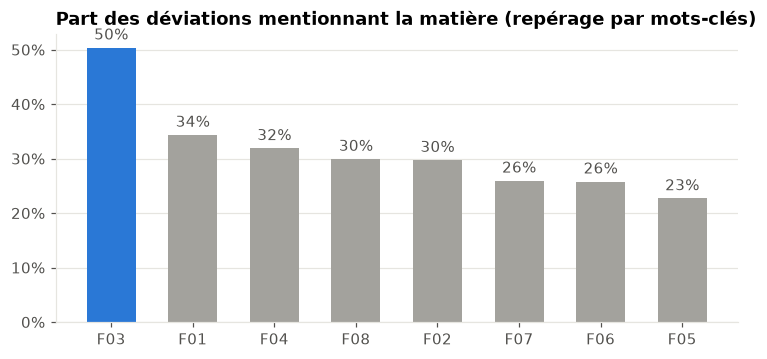

In [14]:
def normaliser(texte):
    texte = unicodedata.normalize("NFKD", str(texte).lower())
    return "".join(c for c in texte if not unicodedata.combining(c))

MOTS_MATIERE = r"matiere premiere|\bmp\b|excipient|fournisseur|\bfut\b|conditionnement|quarantaine|certificat"
dev["mots_matiere"] = dev["description_libre"].map(normaliser).str.contains(MOTS_MATIERE, regex=True)

part_matiere = dev.groupby("id_facconnier")["mots_matiere"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.4))
couleurs = [ACCENT if i == 0 else CONTEXTE for i in range(len(part_matiere))]
barres = ax.bar(part_matiere.index, part_matiere.values, color=couleurs, width=0.6)
ax.bar_label(barres, labels=[f"{v:.0%}" for v in part_matiere.values], padding=3, color=ENCRE)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Part des déviations mentionnant la matière (repérage par mots-clés)")
ax.grid(axis="x", visible=False)
enregistrer(fig, "05_mots_cles_matiere")
plt.show()

In [15]:
taille = lots_p.groupby("gros_lot").agg(lots=("id_lot", "size"), taux_deviation=("avec_deviation", "mean"))
taille.index = ["≤ 50 000 unités", "> 50 000 unités"]
print("Taux de déviation selon la taille du lot :")
print(taille.to_string(formatters={"taux_deviation": "{:.1%}".format}))
print("\nLe lien entre taille de lot et type de cause (Méthode ?) sera étudié en phase 4, une fois les causes classées.")

Taux de déviation selon la taille du lot :
                  lots taux_deviation
≤ 50 000 unités  10899          10.2%
> 50 000 unités    836          13.6%

Le lien entre taille de lot et type de cause (Méthode ?) sera étudié en phase 4, une fois les causes classées.


## 7. Synthèse : ce que disent les données

La cellule suivante produit automatiquement les constats chiffrés, pour qu'ils restent justes si les données sont régénérées.

In [16]:
virgule = lambda texte: texte.replace(".", ",")
sol = saisonnalite.loc["Solaire"] if "Solaire" in saisonnalite.index else None
f_mat = part_matiere.index[0]

constats = [
    f"1. **{cible} ({noms[cible]}) se dégrade depuis début 2025** (rupture estimée en {rupture:%m/%Y}) : OTIF de {avant['otif'].mean():.0%} "
    f"à {apres['otif'].mean():.0%} (p-value {formater_p(p)}), alors que les autres façonniers restent à "
    f"{autres['otif'].mean():.0%}. Cause principale : les retards (à l'heure {avant['a_l_heure'].mean():.0%} "
    f"-> {apres['a_l_heure'].mean():.0%}). → Recommandation : revue de performance et plan d'action avec le façonnier.",
]
if sol is not None:
    constats.append(
        f"2. **Saisonnalité de la gamme {saisonnalite.index[0]}** : {sol['à l\'heure mars-mai']:.0%} de livraisons à l'heure "
        f"en mars-mai contre {sol['à l\'heure reste de l\'année']:.0%} le reste de l'année, effet présent chaque année. "
        f"→ Recommandation : anticiper les commandes de printemps (pic de charge avant l'été)."
    )
constats += [
    f"3. **Les produits complexes sont rejetés {virgule(f'{ratio_rejet:.1f}')} fois plus souvent** ({virgule(f'{c3['rejete'].mean():.1%}')} contre "
    f"{virgule(f'{c12['rejete'].mean():.1%}')}, p-value {formater_p(p_rejet)}), et l'effet se retrouve chez "
    f"{int((controle['ratio 3 / (1-2)'] > 1).sum())} façonniers sur {len(controle)} : c'est bien la complexité, pas le façonnier. "
    f"→ Recommandation : renforcer les contrôles et le transfert technique sur les produits de complexité 3.",
    f"4. **{f_mat} concentre les déviations liées à la matière** ({part_matiere.iloc[0]:.0%} des descriptions, "
    f"contre {part_matiere.iloc[1:].min():.0%} à {part_matiere.iloc[1:].max():.0%} ailleurs, repérage par mots-clés). "
    f"→ À confirmer par la classification IA (phase 4) ; piste : audit de la gestion des matières premières.",
]
from IPython.display import Markdown
Markdown("\n\n".join(constats))

1. **F06 (Wisla Contract Manufacturing) se dégrade depuis début 2025** (rupture estimée en 02/2025) : OTIF de 88% à 73% (p-value < 0,001), alors que les autres façonniers restent à 86%. Cause principale : les retards (à l'heure 93% -> 79%). → Recommandation : revue de performance et plan d'action avec le façonnier.

2. **Saisonnalité de la gamme Solaire** : 85% de livraisons à l'heure en mars-mai contre 96% le reste de l'année, effet présent chaque année. → Recommandation : anticiper les commandes de printemps (pic de charge avant l'été).

3. **Les produits complexes sont rejetés 1,9 fois plus souvent** (4,6% contre 2,4%, p-value < 0,001), et l'effet se retrouve chez 7 façonniers sur 8 : c'est bien la complexité, pas le façonnier. → Recommandation : renforcer les contrôles et le transfert technique sur les produits de complexité 3.

4. **F03 concentre les déviations liées à la matière** (50% des descriptions, contre 23% à 34% ailleurs, repérage par mots-clés). → À confirmer par la classification IA (phase 4) ; piste : audit de la gestion des matières premières.

## 8. Validation contre les tables de vérité

C'est la seule fois où l'on ouvre `data/reference/verite/`. On recalcule les mêmes indicateurs sur les données d'origine (avant l'injection des anomalies) et on compare : si le nettoyage Alteryx est bon, les écarts doivent être faibles.

In [17]:
VERITE = RACINE / "data" / "reference" / "verite"
v_cmd = pd.read_csv(VERITE / "fact_commande.csv", parse_dates=["date_promise", "date_livraison"])
v_lots = pd.read_csv(VERITE / "fact_lot.csv")
v_prod = pd.read_csv(VERITE / "dim_produit.csv")

v_otif = v_cmd[v_cmd["statut_commande"].eq("livrée") & (v_cmd["date_promise"] <= FIN_PERIODE)].copy()
v_otif["otif"] = ((v_otif["date_livraison"] - v_otif["date_promise"]).dt.days <= TOLERANCE_RETARD_J) & \
                 (v_otif["qte_conforme"] >= SEUIL_IN_FULL * v_otif["qte_commandee"])

v_lots = v_lots.merge(v_cmd[["id_commande", "sku", "id_facconnier"]], on="id_commande").merge(v_prod[["sku", "complexite"]], on="sku")

validation = pd.DataFrame({
    "OTIF (pipeline)": otif.groupby("id_facconnier")["otif"].mean(),
    "OTIF (vérité)": v_otif.groupby("id_facconnier")["otif"].mean(),
})
validation["écart (pts)"] = 100 * (validation["OTIF (pipeline)"] - validation["OTIF (vérité)"])

rejet_val = pd.DataFrame({
    "rejet (pipeline)": lots_p.groupby("complexite")["rejete"].mean(),
    "rejet (vérité)": v_lots.groupby("complexite")["statut_lot"].apply(lambda s: s.eq("rejeté").mean()),
})
print(f"Écart maximal d'OTIF par façonnier : {validation['écart (pts)'].abs().max():.1f} point(s)")
v_dev = pd.read_csv(VERITE / "fact_deviation.csv")
v_dev = v_dev.merge(v_lots[["id_lot", "id_facconnier"]], on="id_lot")
part_matiere_verite = v_dev.groupby("id_facconnier")["categorie_6m_verite"].apply(lambda s: s.eq("Matière").mean())

signaux = pd.DataFrame([
    {"signal": "Façonnier dégradé", "trouvé par l'analyse": cible, "attendu (config / vérité)": "F06"},
    {"signal": "Début de la dégradation", "trouvé par l'analyse": f"{rupture:%m/%Y}", "attendu (config / vérité)": "03/2025"},
    {"signal": "Gamme saisonnière", "trouvé par l'analyse": saisonnalite.index[0], "attendu (config / vérité)": "Solaire (mars-mai)"},
    {"signal": "Rejets complexité 3 vs 1-2", "trouvé par l'analyse": f"x{ratio_rejet:.1f}", "attendu (config / vérité)": "x2"},
    {"signal": "Façonnier « Matière »", "trouvé par l'analyse": f"{f_mat} ({part_matiere.iloc[0]:.0%} par mots-clés)",
     "attendu (config / vérité)": f"{part_matiere_verite.idxmax()} ({part_matiere_verite.max():.0%} réel)"},
]).set_index("signal")
display(signaux)
display(validation.style.format({"OTIF (pipeline)": "{:.1%}", "OTIF (vérité)": "{:.1%}", "écart (pts)": "{:+.1f}"}))
display(rejet_val.style.format("{:.2%}"))

Écart maximal d'OTIF par façonnier : 0.5 point(s)


,trouvé par l'analyse,attendu (config / vérité)
signal,,
Façonnier dégradé,F06,F06
Début de la dégradation,02/2025,03/2025
Gamme saisonnière,Solaire,Solaire (mars-mai)
Rejets complexité 3 vs 1-2,x1.9,x2
Façonnier « Matière »,F03 (50% par mots-clés),F03 (54% réel)


,OTIF (pipeline),OTIF (vérité),écart (pts)
id_facconnier,,,
F01,89.8%,90.3%,-0.5
F02,86.5%,86.5%,+0.0
F03,86.1%,86.0%,+0.2
F04,85.3%,85.1%,+0.2
F05,79.7%,79.7%,-0.0
F06,83.1%,82.8%,+0.3
F07,78.3%,78.4%,-0.1
F08,83.7%,84.0%,-0.3


,rejet (pipeline),rejet (vérité)
complexite,,
1,2.12%,2.10%
2,2.53%,2.59%
3,4.59%,4.55%


## 9. Export pour Power BI

Les tables d'analyse enrichies sont exportées dans `data/processed/` pour le tableau de bord de la phase 5. Les graphiques sont enregistrés dans `docs/figures/`.

In [18]:
colonnes_cmd = ["id_commande", "id_facconnier", "nom_facconnier", "sku", "gamme", "complexite",
                "date_commande", "date_promise", "date_livraison", "mois", "qte_commandee", "qte_livree",
                "qte_conforme", "statut_commande", "retard_jours", "a_l_heure", "complete", "otif",
                "dans_perimetre_otif"]
cmd[colonnes_cmd].to_csv(PROCESSED / "analyse_commandes.csv", index=False, encoding="utf-8")

colonnes_lots = ["id_lot", "id_commande", "id_facconnier", "sku", "gamme", "complexite", "date_fabrication",
                 "taille_lot", "gros_lot", "statut_lot", "rejete", "retraite", "avec_deviation", "cout_non_qualite_eur"]
lots_p[colonnes_lots].to_csv(PROCESSED / "analyse_lots.csv", index=False, encoding="utf-8")

print("Exports :", "analyse_commandes.csv", len(cmd), "lignes |", "analyse_lots.csv", len(lots_p), "lignes")
print("Figures :", sorted(p.name for p in FIGURES.glob("*.png")))

Exports : analyse_commandes.csv 6000 lignes | analyse_lots.csv 11735 lignes
Figures : ['01_otif_facconnier_trimestre.png', '02_rupture_otif.png', '03_saisonnalite_gamme_mois.png', '04_rejet_complexite.png', '05_mots_cles_matiere.png']


## Ce que je retiens

- Un indicateur global masque l'essentiel : la dégradation d'un façonnier n'apparaît qu'en découpant **par fournisseur et dans le temps**.
- Une saisonnalité se prouve en vérifiant qu'elle **revient chaque année**, et en écartant les autres effets (ici, la dérive d'un façonnier).
- Avant de conclure qu'un facteur explique un résultat, il faut **contrôler les facteurs cachés** : l'effet de la complexité persiste à l'intérieur de chaque façonnier.
- Les descriptions de déviations en texte libre limitent l'analyse des causes : c'est le point de départ de la **phase 4 (classification IA)**.